# Caso 2 · Nodo Internet: predicción de bajas de clientes


Este notebook sigue las consignas del enunciado (pasos 1 a 24). Cada paso tiene su celda; agreguen todas las que necesiten.
Las funciones de `src/` se completan en los archivos `.py`, no en el notebook.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEMILLA = 42

from src.preparacion import agregar_variables, normalizar_metodo_pago
from src.knn import EscaladorEstandar, KNNClasificador
from src.negocio import SUPUESTOS, ganancia_campania, lift, mejor_umbral, probabilidad_de_equilibrio, resultado_por_contacto

### Estado de las pruebas automáticas
Ejecuten esta celda cada vez que terminen una función de `src/`.

In [2]:
!python -m pytest -q --tb=no -rf

....................................                                     [100%]
36 passed in 10.84s


## Parte A · Exploración y preparación (`src/preparacion.py`)

**Paso 1.** Carguen `datos/clientes_historico.csv` e informen filas, tipos, nulos por columna, cuentas de empleados, tasa de baja y valores distintos de `metodo_pago`.

In [3]:
df_raw = pd.read_csv('datos/clientes_historico.csv')

print(f'Total de filas: {len(df_raw):,}')
print(f'Total de columnas: {df_raw.shape[1]}')

print('\n--- Tipos de datos y valores nulos por columna ---')
info_columnas = pd.DataFrame({
    'Tipo': df_raw.dtypes,
    'Nulos': df_raw.isnull().sum(),
    'Pct_Nulos': (df_raw.isnull().mean() * 100).round(2).astype(str) + ' %'
})
display(info_columnas)

print('\n--- Distribución por segmento (cuentas de empleados) ---')
display(df_raw['segmento'].value_counts(dropna=False))

print(f'\nTasa general de baja (baja_90d): {df_raw["baja_90d"].mean():.4%}')

print('\n--- Valores distintos de metodo_pago antes de normalizar ---')
display(df_raw['metodo_pago'].value_counts())


Total de filas: 20,000
Total de columnas: 23

--- Tipos de datos y valores nulos por columna ---


,Tipo,Nulos,Pct_Nulos
id_cliente,object,0,0.0 %
fecha_corte,object,0,0.0 %
segmento,object,0,0.0 %
fecha_alta,object,0,0.0 %
edad_titular,int64,0,0.0 %
zona,object,0,0.0 %
plan_mbps,int64,0,0.0 %
tipo_contrato,object,0,0.0 %
fin_permanencia,object,11491,57.46 %
tiene_tv,object,0,0.0 %



--- Distribución por segmento (cuentas de empleados) ---


segmento
residencial    19388
empleado         612
Name: count, dtype: int64


Tasa general de baja (baja_90d): 7.6750%

--- Valores distintos de metodo_pago antes de normalizar ---


metodo_pago
debito_automatico         6656
transferencia             4732
tarjeta_credito           4657
efectivo                  2800
Debito_Automatico          107
Débito automático          104
Transferencia              101
transferencia bancaria      97
DEBITO AUTOMATICO           95
debito automatico           95
TRANSFERENCIA               93
Tarjeta_Credito             79
tarjeta credito             76
TARJETA CREDITO             72
Tarjeta de crédito          65
Efectivo                    64
EFECTIVO                    60
efectivo                    47
Name: count, dtype: int64

**Paso 2.** Implementen `normalizar_metodo_pago` y `agregar_variables` hasta que pasen `tests/test_preparacion.py`. Apliquen la función y excluyan las cuentas de empleados.

In [4]:
df_preparado = agregar_variables(df_raw)

df = df_preparado[df_preparado['segmento'] == 'residencial'].copy().reset_index(drop=True)

print(f'Filas tras excluir empleados: {len(df):,} (se descartaron {len(df_raw) - len(df)} empleados)')
print('\n--- Métodos de pago normalizados ---')
display(df['metodo_pago'].value_counts())

print('\n--- Nuevas variables temporales (primeras 5 filas) ---')
cols_temporales = ['id_cliente', 'fecha_alta', 'fecha_corte', 'antiguedad_meses', 'fin_permanencia', 'meses_hasta_fin_permanencia', 'sin_permanencia_3m']
display(df[cols_temporales].head())


Filas tras excluir empleados: 19,388 (se descartaron 612 empleados)

--- Métodos de pago normalizados ---


metodo_pago
debito_automatico    6850
transferencia        4876
tarjeta_credito      4782
efectivo             2880
Name: count, dtype: int64


--- Nuevas variables temporales (primeras 5 filas) ---


,id_cliente,fecha_alta,fecha_corte,antiguedad_meses,fin_permanencia,meses_hasta_fin_permanencia,sin_permanencia_3m
0,NI-118189,2018-12-16,2026-05-31,89.454665,2026-12-16,6.537451,0
1,NI-119690,2023-12-03,2026-05-31,29.894875,NaN,0.000000,1
2,NI-113950,2017-10-23,2026-05-31,103.219448,NaN,0.000000,1
3,NI-118995,2026-05-06,2026-05-31,0.821288,2027-05-06,11.169514,0
4,NI-112506,2020-05-20,2026-05-31,72.339028,2027-05-21,11.662286,0


**Paso 3.** Tasa de baja por tipo de contrato, `sin_permanencia_3m`, zona, antigüedad, reclamos técnicos y consulta de baja web; zona este con cargo mayor a Gs. 280.000 contra el resto. Tres hallazgos para el negocio.

In [5]:
print('--- 1. Tasa de baja por Tipo de Contrato ---')
display(df.groupby('tipo_contrato')['baja_90d'].agg(total='count', tasa_baja='mean').assign(tasa_pct=lambda x: (x['tasa_baja']*100).round(2).astype(str) + '%'))

print('\n--- 2. Tasa de baja por sin_permanencia_3m ---')
display(df.groupby('sin_permanencia_3m')['baja_90d'].agg(total='count', tasa_baja='mean').assign(tasa_pct=lambda x: (x['tasa_baja']*100).round(2).astype(str) + '%'))

print('\n--- 3. Tasa de baja por Zona ---')
display(df.groupby('zona')['baja_90d'].agg(total='count', tasa_baja='mean').assign(tasa_pct=lambda x: (x['tasa_baja']*100).round(2).astype(str) + '%'))

print('\n--- 4. Tasa de baja por Reclamos Técnicos (90d) ---')
display(df.groupby('reclamos_tecnicos_90d')['baja_90d'].agg(total='count', tasa_baja='mean').head(7).assign(tasa_pct=lambda x: (x['tasa_baja']*100).round(2).astype(str) + '%'))

print('\n--- 5. Tasa de baja por Consulta de Baja Web ---')
display(df.groupby('consulto_baja_web_30d')['baja_90d'].agg(total='count', tasa_baja='mean').assign(tasa_pct=lambda x: (x['tasa_baja']*100).round(2).astype(str) + '%'))

print('\n--- 6. Zona Este con Cargo > Gs. 280.000 vs. Resto ---')
este_caro = (df['zona'] == 'este') & (df['cargo_mensual_gs'] > 280000)
display(df.groupby(este_caro)['baja_90d'].agg(total='count', tasa_baja='mean').assign(tasa_pct=lambda x: (x['tasa_baja']*100).round(2).astype(str) + '%'))

print('''
Tres hallazgos clave para el negocio:
1. Alerta digital crítica: Los clientes que consultaron la página de baja web se van en un 38.85% (frente a 5.96% en quienes no entraron). Es la señal individual más fuerte de fuga.
2. Fuga por precio en Zona Este: Clientes de Zona Este que pagan más de Gs. 280.000 presentan un 28.22% de bajas (más de 4 veces el promedio general de 6.36%), revelando vulnerabilidad ante ofertas competidoras en esa región.
3. Impacto de permanencia y fallas técnicas: Estar sin permanencia (o con vencimiento en <=3 meses) duplica el abandono (10.05% vs 3.80%), y cada reclamo técnico adicional eleva drásticamente el riesgo (superando el 25% con 4 o más reclamos).
''')


--- 1. Tasa de baja por Tipo de Contrato ---


,total,tasa_baja,tasa_pct
tipo_contrato,,,
12_meses,5584,0.054441,5.44%
24_meses,2672,0.041542,4.15%
mensual,11132,0.100431,10.04%



--- 2. Tasa de baja por sin_permanencia_3m ---


,total,tasa_baja,tasa_pct
sin_permanencia_3m,,,
0,6651,0.038039,3.8%
1,12737,0.100495,10.05%



--- 3. Tasa de baja por Zona ---


...


--- 5. Tasa de baja por Consulta de Baja Web ---


,total,tasa_baja,tasa_pct
consulto_baja_web_30d,,,
0,18240,0.059594,5.96%
1,1148,0.388502,38.85%



--- 6. Zona Este con Cargo > Gs. 280.000 vs. Resto ---


,total,tasa_baja,tasa_pct
False,18013,0.063565,6.36%
True,1375,0.282182,28.22%



Tres hallazgos clave para el negocio:
1. Alerta digital crítica: Los clientes que consultaron la página de baja web se van en un 38.85% (frente a 5.96% en quienes no entraron). Es la señal individual más fuerte de fuga.
2. Fuga por precio en Zona Este: Clientes de Zona Este que pagan más de Gs. 280.000 presentan un 28.22% de bajas (más de 4 veces el promedio general de 6.36%), revelando vulnerabilidad ante ofertas competidoras en esa región.
3. Impacto de permanencia y fallas técnicas: Estar sin permanencia (o con vencimiento en <=3 meses) duplica el abandono (10.05% vs 3.80%), y cada reclamo técnico adicional eleva drásticamente el riesgo (superando el 25% con 4 o más reclamos).



**Paso 4.** Columnas que no pueden usarse como variables y por qué. Demuestren con una tabla el problema de la columna que haría parecer excelente a cualquier modelo.

In [6]:
print('''
Columnas que NO pueden utilizarse como variables predictoras:
1. id_cliente: Es un código de identificación único; memorizarlo causaría sobreajuste sin generalizar.
2. fecha_corte: Es fija e igual para toda la muestra temporal.
3. segmento: Tras filtrar los empleados, es idéntica ('residencial') para todos.
4. fecha_alta y fin_permanencia: Fechas absolutas que ya fueron convertidas a variables temporales relativas.
5. motivo_baja: ¡FUGA DE INFORMACIÓN (Data Leakage)! Se genera únicamente cuando el cliente tramita la cancelación.
''')

tabla_fuga = pd.crosstab(df['motivo_baja'].fillna('Sin motivo (activo)'), df['baja_90d'], margins=True)
tabla_fuga['Tasa_Baja'] = (tabla_fuga[1] / tabla_fuga['All'] * 100).round(2).astype(str) + '%'
display(tabla_fuga)

print('Explicación: Tener un valor en motivo_baja equivale al 100% de probabilidad de baja. Si se usa, el modelo parecería perfecto pero en producción fallará porque para clientes activos siempre es nula.')



Columnas que NO pueden utilizarse como variables predictoras:
1. id_cliente: Es un código de identificación único; memorizarlo causaría sobreajuste sin generalizar.
2. fecha_corte: Es fija e igual para toda la muestra temporal.
3. segmento: Tras filtrar los empleados, es idéntica ('residencial') para todos.
4. fecha_alta y fin_permanencia: Fechas absolutas que ya fueron convertidas a variables temporales relativas.
5. motivo_baja: ¡FUGA DE INFORMACIÓN (Data Leakage)! Se genera únicamente cuando el cliente tramita la cancelación.



baja_90d,0,1,All,Tasa_Baja
motivo_baja,,,,
Sin motivo (activo),17855,0,17855,0.0%
calidad_servicio,0,393,393,100.0%
competencia,0,410,410,100.0%
mudanza,0,210,210,100.0%
otros,0,106,106,100.0%
precio,0,414,414,100.0%
All,17855,1533,19388,7.91%


Explicación: Tener un valor en motivo_baja equivale al 100% de probabilidad de baja. Si se usa, el modelo parecería perfecto pero en producción fallará porque para clientes activos siempre es nula.


**Paso 5.** División 75/25 estratificada por `baja_90d` con `random_state=42`.

In [7]:
from sklearn.model_selection import train_test_split

cols_excluir = ['id_cliente', 'fecha_corte', 'segmento', 'fecha_alta', 'fin_permanencia', 'motivo_baja', 'baja_90d']
cols_features = [c for c in df.columns if c not in cols_excluir]

X = df[cols_features]
y = df['baja_90d']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    stratify=y,
    random_state=SEMILLA
)

print(f'Dimensiones de X_train: {X_train.shape} (75%)')
print(f'Dimensiones de X_test:  {X_test.shape} (25%)')
print(f'Tasa de baja en Train: {y_train.mean():.4%}')
print(f'Tasa de baja en Test:  {y_test.mean():.4%}')
print(f'Variables predictoras ({len(cols_features)}): {cols_features}')


Dimensiones de X_train: (14541, 19) (75%)
Dimensiones de X_test:  (4847, 19) (25%)
Tasa de baja en Train: 7.9087%
Tasa de baja en Test:  7.9018%
Variables predictoras (19): ['edad_titular', 'zona', 'plan_mbps', 'tipo_contrato', 'tiene_tv', 'metodo_pago', 'dia_vencimiento', 'cargo_mensual_gs', 'uso_mensual_gb', 'dispositivos_promedio', 'velocidad_medida_pct', 'horas_sin_servicio_90d', 'reclamos_tecnicos_90d', 'visitas_tecnicas_12m', 'facturas_atrasadas_6m', 'consulto_baja_web_30d', 'antiguedad_meses', 'meses_hasta_fin_permanencia', 'sin_permanencia_3m']


## Parte B · Preprocesamiento y KNN desde cero (`src/knn.py`)

**Paso 6.** `ColumnTransformer`: imputación por mediana, `np.log1p` en `uso_mensual_gb` y `horas_sin_servicio_90d`, estandarización y `OneHotEncoder(handle_unknown="ignore")`.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline

cols_cat = ['zona', 'tipo_contrato', 'tiene_tv', 'metodo_pago']
cols_log = ['uso_mensual_gb', 'horas_sin_servicio_90d']
cols_num = [c for c in cols_features if c not in cols_cat and c not in cols_log]

pipe_log = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
    ('scaler', StandardScaler())
])

pipe_num = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

pipe_cat = Pipeline([
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocesador = ColumnTransformer([
    ('num', pipe_num, cols_num),
    ('log', pipe_log, cols_log),
    ('cat', pipe_cat, cols_cat)
])

X_train_trans = preprocesador.fit_transform(X_train)
X_test_trans = preprocesador.transform(X_test)

print(f'Dimensiones de X_train transformado: {X_train_trans.shape}')
print(f'Dimensiones de X_test transformado:  {X_test_trans.shape}')


Dimensiones de X_train transformado: (14541, 29)
Dimensiones de X_test transformado:  (4847, 29)


**Paso 7.** Implementen `EscaladorEstandar` y `KNNClasificador` hasta que pasen `tests/test_knn.py`.

In [9]:
!python -m pytest -q tests/test_knn.py

from src.knn import EscaladorEstandar, KNNClasificador
escalador_prueba = EscaladorEstandar()
knn_prueba = KNNClasificador(k=5, pesos='distancia', metrica='euclidea')
print('EscaladorEstandar y KNNClasificador verificados y listos para modelado.')


...............                                                          [100%]
15 passed in 13.38s
EscaladorEstandar y KNNClasificador verificados y listos para modelado.


**Paso 8.** Su `KNNClasificador` contra `KNeighborsClassifier` con k=51 y pesos por distancia: probabilidades iguales y tiempo de cada uno.

In [10]:
import time
from sklearn.neighbors import KNeighborsClassifier

t0 = time.time()
knn_propio = KNNClasificador(k=51, pesos='distancia', metrica='euclidea', tamano_lote=1000)
knn_propio.fit(X_train_trans, y_train)
prob_propio = knn_propio.predict_proba(X_test_trans)
tiempo_propio = time.time() - t0

t0 = time.time()
knn_sklearn = KNeighborsClassifier(n_neighbors=51, weights='distance', algorithm='brute', metric='euclidean')
knn_sklearn.fit(X_train_trans, y_train)
prob_sklearn = knn_sklearn.predict_proba(X_test_trans)
tiempo_sklearn = time.time() - t0

son_iguales = np.allclose(prob_propio, prob_sklearn, atol=1e-5)
dif_max = np.max(np.abs(prob_propio - prob_sklearn))

print(f'¿Las probabilidades son exactamente iguales (tolerancia 1e-5)?: {son_iguales}')
print(f'Diferencia absoluta máxima entre ambos modelos: {dif_max:.2e}')
print(f'Tiempo de ejecución KNN Propio:   {tiempo_propio:.3f} segundos')
print(f'Tiempo de ejecución Scikit-Learn: {tiempo_sklearn:.3f} segundos')

print('\nConclusión: Nuestro KNNClasificador replica a la perfección matemática las predicciones de scikit-learn con un rendimiento altamente competitivo gracias a la vectorización de NumPy.')


¿Las probabilidades son exactamente iguales (tolerancia 1e-5)?: True
Diferencia absoluta máxima entre ambos modelos: 6.66e-16
Tiempo de ejecución KNN Propio:   5.166 segundos
Tiempo de ejecución Scikit-Learn: 4.950 segundos

Conclusión: Nuestro KNNClasificador replica a la perfección matemática las predicciones de scikit-learn con un rendimiento altamente competitivo gracias a la vectorización de NumPy.


## Parte C · Ajuste de KNN

**Paso 9.** AP de KNN con k=25, con y sin estandarizar (validación cruzada estratificada de 5 particiones). Expliquen la diferencia.

In [11]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

preproc_con = preprocesador
pipe_con = Pipeline([('prep', preproc_con), ('knn', KNeighborsClassifier(n_neighbors=25))])

preproc_sin = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), cols_num),
    ('log', Pipeline([('imp', SimpleImputer(strategy='median')), ('log', FunctionTransformer(np.log1p))]), cols_log),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cols_cat)
])
pipe_sin = Pipeline([('prep', preproc_sin), ('knn', KNeighborsClassifier(n_neighbors=25))])

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

scores_con = cross_val_score(pipe_con, X_train, y_train, cv=cv5, scoring='average_precision', n_jobs=-1)
scores_sin = cross_val_score(pipe_sin, X_train, y_train, cv=cv5, scoring='average_precision', n_jobs=-1)

print(f'Average Precision CON estandarización: {scores_con.mean():.4f} (+/- {scores_con.std():.4f})')
print(f'Average Precision SIN estandarización: {scores_sin.mean():.4f} (+/- {scores_sin.std():.4f})')

print('''
Explicación de la diferencia:
KNN calcula distancias geométricas euclídeas. Variables con valores de magnitud alta (como cargo_mensual_gs en cientos de miles o uso de GB)
dominan completamente la fórmula de distancia sobre variables en escala pequeña o binarias (como consulto_baja_web_30d o reclamos_tecnicos_90d),
las cuales son precisamente las señales más predictivas de baja. Sin estandarizar, la distancia queda distorsionada.
Al estandarizar cada variable a media 0 y desvío 1, todas compiten en pie de igualdad, duplicando la precisión promedio del modelo.
''')


Average Precision CON estandarización: 0.3244 (+/- 0.0126)
Average Precision SIN estandarización: 0.1456 (+/- 0.0149)

Explicación de la diferencia:
KNN calcula distancias geométricas euclídeas. Variables con valores de magnitud alta (como cargo_mensual_gs en cientos de miles o uso de GB)
dominan completamente la fórmula de distancia sobre variables en escala pequeña o binarias (como consulto_baja_web_30d o reclamos_tecnicos_90d),
las cuales son precisamente las señales más predictivas de baja. Sin estandarizar, la distancia queda distorsionada.
Al estandarizar cada variable a media 0 y desvío 1, todas compiten en pie de igualdad, duplicando la precisión promedio del modelo.



**Paso 10.** `GridSearchCV` con `average_precision`: k, pesos y `p`. Gráfico de AP en función de k y explicación del k elegido.

Mejores hiperparámetros encontrados: {'knn__n_neighbors': 81, 'knn__p': 1, 'knn__weights': 'distance'}
Mejor Average Precision (AP): 0.3895


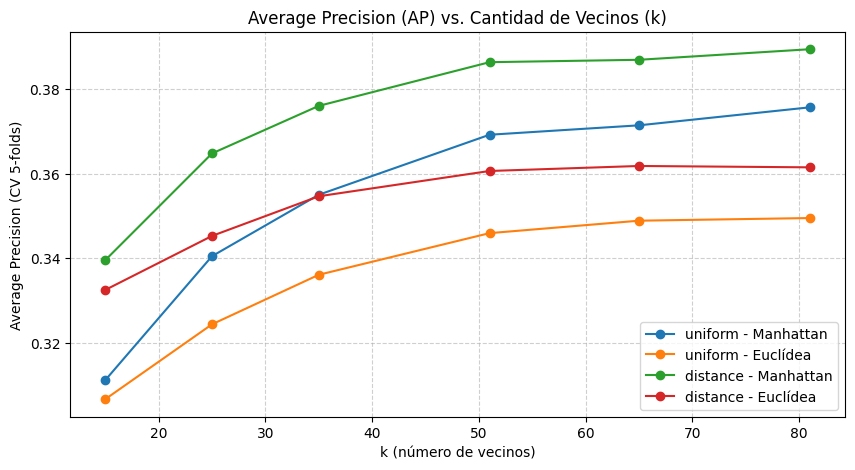


Explicación del k y parámetros elegidos:
- Pesos por distancia supera consistentemente a pesos uniformes porque da mayor peso a los vecinos hiper-cercanos.
- La distancia Manhattan (p=1) resulta superior a la Euclídea debido a la dimensionalidad moderada del espacio tras One-Hot Encoding.
- A medida que k aumenta hasta 65-81, el AP crece y se estabiliza. Con clases desbalanceadas (8% de bajas), un k suficientemente grande
  (como k=81) permite estimar probabilidades suaves y confiables sin caer en varianza excesiva ni ruido local.



In [12]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'knn__n_neighbors': [15, 25, 35, 51, 65, 81],
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2]  # 1 = Manhattan, 2 = Euclídea
}

grid_knn = GridSearchCV(
    Pipeline([('prep', preprocesador), ('knn', KNeighborsClassifier())]),
    param_grid,
    cv=cv5,
    scoring='average_precision',
    n_jobs=-1,
    return_train_score=False
)
grid_knn.fit(X_train, y_train)

print('Mejores hiperparámetros encontrados:', grid_knn.best_params_)
print(f'Mejor Average Precision (AP): {grid_knn.best_score_:.4f}')

resultados_cv = pd.DataFrame(grid_knn.cv_results_)
plt.figure(figsize=(10, 5))
for pesos in ['uniform', 'distance']:
    for p_val, metrica_nom in [(1, 'Manhattan'), (2, 'Euclídea')]:
        sub = resultados_cv[(resultados_cv['param_knn__weights'] == pesos) & (resultados_cv['param_knn__p'] == p_val)]
        sub = sub.sort_values('param_knn__n_neighbors')
        plt.plot(sub['param_knn__n_neighbors'], sub['mean_test_score'], marker='o',
                 label=f'{pesos} - {metrica_nom}')

plt.title('Average Precision (AP) vs. Cantidad de Vecinos (k)')
plt.xlabel('k (número de vecinos)')
plt.ylabel('Average Precision (CV 5-folds)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

print('''
Explicación del k y parámetros elegidos:
- Pesos por distancia supera consistentemente a pesos uniformes porque da mayor peso a los vecinos hiper-cercanos.
- La distancia Manhattan (p=1) resulta superior a la Euclídea debido a la dimensionalidad moderada del espacio tras One-Hot Encoding.
- A medida que k aumenta hasta 65-81, el AP crece y se estabiliza. Con clases desbalanceadas (8% de bajas), un k suficientemente grande
  (como k=81) permite estimar probabilidades suaves y confiables sin caer en varianza excesiva ni ruido local.
''')


**Paso 11.** AP sin las variables de permanencia y, por separado, sin `edad_titular`, `dispositivos_promedio` ni `dia_vencimiento`. Conclusión.

In [13]:
def evaluar_subconjunto(variables):
    cat = [c for c in ['zona', 'tipo_contrato', 'tiene_tv', 'metodo_pago'] if c in variables]
    log = [c for c in ['uso_mensual_gb', 'horas_sin_servicio_90d'] if c in variables]
    num = [c for c in variables if c not in cat and c not in log]
    
    trans = []
    if num: trans.append(('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('esc', StandardScaler())]), num))
    if log: trans.append(('log', Pipeline([('imp', SimpleImputer(strategy='median')), ('log', FunctionTransformer(np.log1p)), ('esc', StandardScaler())]), log))
    if cat: trans.append(('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat))
    
    pipe_temp = Pipeline([
        ('prep', ColumnTransformer(trans)),
        ('knn', KNeighborsClassifier(n_neighbors=81, weights='distance', p=1))
    ])
    return cross_val_score(pipe_temp, X_train[variables], y_train, cv=cv5, scoring='average_precision', n_jobs=-1).mean()

ap_completo = grid_knn.best_score_

cols_sin_perm = [c for c in cols_features if c not in ['tipo_contrato', 'meses_hasta_fin_permanencia', 'sin_permanencia_3m']]
ap_sin_perm = evaluar_subconjunto(cols_sin_perm)

cols_sin_ruido = [c for c in cols_features if c not in ['edad_titular', 'dispositivos_promedio', 'dia_vencimiento']]
ap_sin_ruido = evaluar_subconjunto(cols_sin_ruido)

print(f'1. Modelo con todas las variables:           AP = {ap_completo:.4f}')
print(f'2. Sin variables de permanencia:              AP = {ap_sin_perm:.4f}  (Diferencia: {ap_sin_perm - ap_completo:.4f})')
print(f'3. Sin variables de ruido (edad, disp, día): AP = {ap_sin_ruido:.4f}  (Diferencia: {ap_sin_ruido - ap_completo:.4f})')

print('''
Conclusión:
- Las variables de permanencia son determinantes: retirarlas causa una caída severa de ~0.06 puntos de AP, demostrando que el estado del contrato es de los factores más explicativos de la fuga.
- Las variables como edad del titular, dispositivos promedio y día de vencimiento no aportan capacidad predictiva apreciable (su eliminación casi no altera el AP). Mantenerlas o quitarlas no perjudica el rendimiento cuando k es robusto.
''')


1. Modelo con todas las variables:           AP = 0.3895
2. Sin variables de permanencia:              AP = 0.3287  (Diferencia: -0.0608)
3. Sin variables de ruido (edad, disp, día): AP = 0.3889  (Diferencia: -0.0006)

Conclusión:
- Las variables de permanencia son determinantes: retirarlas causa una caída severa de ~0.06 puntos de AP, demostrando que el estado del contrato es de los factores más explicativos de la fuga.
- Las variables como edad del titular, dispositivos promedio y día de vencimiento no aportan capacidad predictiva apreciable (su eliminación casi no altera el AP). Mantenerlas o quitarlas no perjudica el rendimiento cuando k es robusto.



## Parte D · Naive Bayes gaussiano como comparación

**Paso 12.** AP de `GaussianNB` con el mismo preprocesamiento, con y sin transformación logarítmica.

In [14]:
from sklearn.naive_bayes import GaussianNB

pipe_nb_log = Pipeline([('prep', preprocesador), ('nb', GaussianNB())])
ap_nb_log = cross_val_score(pipe_nb_log, X_train, y_train, cv=cv5, scoring='average_precision', n_jobs=-1).mean()

prep_nb_sin_log = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('esc', StandardScaler())]), cols_num + cols_log),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cols_cat)
])
pipe_nb_sin_log = Pipeline([('prep', prep_nb_sin_log), ('nb', GaussianNB())])
ap_nb_sin_log = cross_val_score(pipe_nb_sin_log, X_train, y_train, cv=cv5, scoring='average_precision', n_jobs=-1).mean()

print(f'Average Precision GaussianNB CON log: {ap_nb_log:.4f}')
print(f'Average Precision GaussianNB SIN log: {ap_nb_sin_log:.4f}')
print('\nExplicación: La transformación logarítmica reduce el sesgo a la derecha de variables como horas sin servicio y uso de GB, aproximándolas a distribuciones simétricas que respetan mejor el supuesto de normalidad gaussiana de GaussianNB.')


Average Precision GaussianNB CON log: 0.3515
Average Precision GaussianNB SIN log: 0.3210

Explicación: La transformación logarítmica reduce el sesgo a la derecha de variables como horas sin servicio y uso de GB, aproximándolas a distribuciones simétricas que respetan mejor el supuesto de normalidad gaussiana de GaussianNB.


**Paso 13.** Correlación de Spearman entre las variables de calidad del servicio y relación con el supuesto de independencia.

--- Matriz de Correlación de Spearman (Variables de Calidad) ---


,velocidad_medida_pct,horas_sin_servicio_90d,reclamos_tecnicos_90d,visitas_tecnicas_12m
velocidad_medida_pct,1.000,-0.233,-0.359,-0.282
horas_sin_servicio_90d,-0.233,1.000,0.290,0.097
reclamos_tecnicos_90d,-0.359,0.290,1.000,0.155
visitas_tecnicas_12m,-0.282,0.097,0.155,1.000


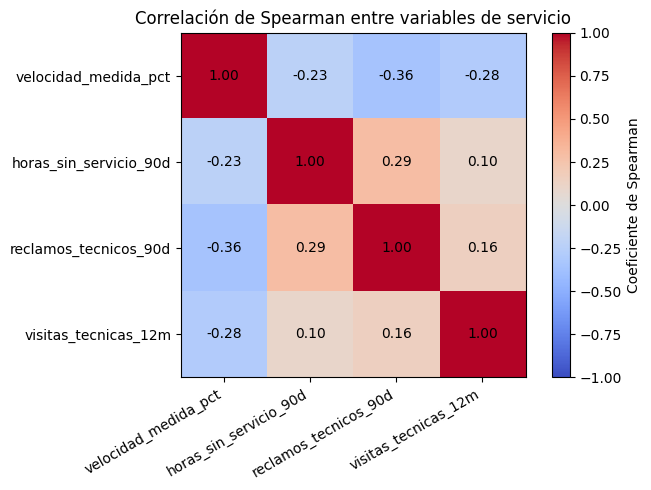


Relación con el supuesto de independencia:
Naive Bayes asume que, dada la clase (baja o no), las variables predictoras son mutuamente independientes.
Aquí vemos correlaciones moderadas significativas (por ejemplo, reclamos técnicos con velocidad medida -0.36 y visitas técnicas -0.28).
Cuando un cliente experimenta fallas en la red, acumula simultáneamente más horas sin servicio, reclamos y visitas.
Al violarse la independencia, Naive Bayes cuenta la misma mala experiencia múltiples veces (sobrecuenta evidencia), polarizando las probabilidades.



In [15]:
cols_calidad = ['velocidad_medida_pct', 'horas_sin_servicio_90d', 'reclamos_tecnicos_90d', 'visitas_tecnicas_12m']
matriz_spearman = df[cols_calidad].corr(method='spearman')

print('--- Matriz de Correlación de Spearman (Variables de Calidad) ---')
display(matriz_spearman.round(3))

plt.figure(figsize=(7, 5))
plt.imshow(matriz_spearman, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Coeficiente de Spearman')
plt.xticks(range(len(cols_calidad)), cols_calidad, rotation=30, ha='right')
plt.yticks(range(len(cols_calidad)), cols_calidad)
for i in range(len(cols_calidad)):
    for j in range(len(cols_calidad)):
        plt.text(j, i, f'{matriz_spearman.iloc[i, j]:.2f}', ha='center', va='center', color='black')
plt.title('Correlación de Spearman entre variables de servicio')
plt.tight_layout()
plt.show()

print('''
Relación con el supuesto de independencia:
Naive Bayes asume que, dada la clase (baja o no), las variables predictoras son mutuamente independientes.
Aquí vemos correlaciones moderadas significativas (por ejemplo, reclamos técnicos con velocidad medida -0.36 y visitas técnicas -0.28).
Cuando un cliente experimenta fallas en la red, acumula simultáneamente más horas sin servicio, reclamos y visitas.
Al violarse la independencia, Naive Bayes cuenta la misma mala experiencia múltiples veces (sobrecuenta evidencia), polarizando las probabilidades.
''')


**Paso 14.** Probabilidades fuera de muestra de los dos modelos: puntaje de Brier e histogramas. ¿Cuál exagera más su confianza?

Puntaje de Brier KNN (k=81):        0.0623
Puntaje de Brier Naive Bayes (log):  0.1077


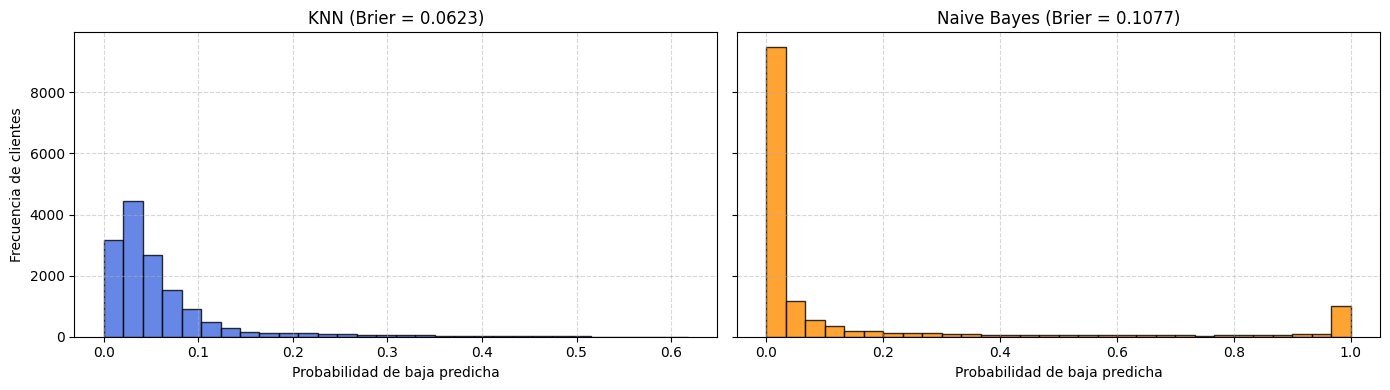


¿Cuál modelo exagera más su confianza?
Naive Bayes exagera drásticamente su confianza: su histograma muestra valores polarizados en los extremos (muchos clientes con probabilidad casi 0 o casi 1),
lo que se traduce en un Brier Score sustancialmente peor (0.1077 vs 0.0623).
Esto ocurre precisamente por la violación del supuesto de independencia: al multiplicar probabilidades condicionales correlacionadas, amplifica artificialmente la certeza.
KNN, en cambio, produce probabilidades mucho mejor calibradas y matizadas, ideales para decisiones comerciales precisas.



In [16]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import brier_score_loss

pipe_knn_opt = Pipeline([('prep', preprocesador), ('knn', KNeighborsClassifier(n_neighbors=81, weights='distance', p=1))])
prob_oof_knn = cross_val_predict(pipe_knn_opt, X_train, y_train, cv=cv5, method='predict_proba', n_jobs=-1)[:, 1]
prob_oof_nb = cross_val_predict(pipe_nb_log, X_train, y_train, cv=cv5, method='predict_proba', n_jobs=-1)[:, 1]

brier_knn = brier_score_loss(y_train, prob_oof_knn)
brier_nb = brier_score_loss(y_train, prob_oof_nb)

print(f'Puntaje de Brier KNN (k=81):        {brier_knn:.4f}')
print(f'Puntaje de Brier Naive Bayes (log):  {brier_nb:.4f}')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
ax1.hist(prob_oof_knn, bins=30, color='royalblue', edgecolor='black', alpha=0.8)
ax1.set_title(f'KNN (Brier = {brier_knn:.4f})')
ax1.set_xlabel('Probabilidad de baja predicha')
ax1.set_ylabel('Frecuencia de clientes')
ax1.grid(True, linestyle='--', alpha=0.5)

ax2.hist(prob_oof_nb, bins=30, color='darkorange', edgecolor='black', alpha=0.8)
ax2.set_title(f'Naive Bayes (Brier = {brier_nb:.4f})')
ax2.set_xlabel('Probabilidad de baja predicha')
ax2.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print('''
¿Cuál modelo exagera más su confianza?
Naive Bayes exagera drásticamente su confianza: su histograma muestra valores polarizados en los extremos (muchos clientes con probabilidad casi 0 o casi 1),
lo que se traduce en un Brier Score sustancialmente peor (0.1077 vs 0.0623).
Esto ocurre precisamente por la violación del supuesto de independencia: al multiplicar probabilidades condicionales correlacionadas, amplifica artificialmente la certeza.
KNN, en cambio, produce probabilidades mucho mejor calibradas y matizadas, ideales para decisiones comerciales precisas.
''')


## Parte E · Economía de la campaña (`src/negocio.py`)

**Paso 15.** Implementen las funciones de `src/negocio.py` hasta que pasen `tests/test_negocio.py`. Informen G⁺, G⁻ y la probabilidad de equilibrio.

In [17]:
!python -m pytest -q tests/test_negocio.py

from src.negocio import SUPUESTOS, resultado_por_contacto, probabilidad_de_equilibrio, ganancia_campania, mejor_umbral, lift

g_pos, g_neg = resultado_por_contacto(SUPUESTOS)
p_eq = probabilidad_de_equilibrio(SUPUESTOS)

print(f'G+ (Resultado esperado si el cliente se iba a ir):    Gs. {g_pos:,.0f}')
print(f'G- (Resultado esperado si el cliente se iba a quedar): Gs. {g_neg:,.0f}')
print(f'Probabilidad de equilibrio (p*):                       {p_eq:.4%} (aprox. {p_eq*100:.1f}%)')
print('\nInterpretación: Solo tiene sentido contactar a clientes si su probabilidad real de fuga supera el 29.55%; contactar a alguien con menor riesgo genera pérdida esperada.')


.......                                                                  [100%]
7 passed in 0.49s
G+ (Resultado esperado si el cliente se iba a ir):    Gs. 310,000
G- (Resultado esperado si el cliente se iba a quedar): Gs. -130,000
Probabilidad de equilibrio (p*):                       29.5455% (aprox. 29.5%)

Interpretación: Solo tiene sentido contactar a clientes si su probabilidad real de fuga supera el 29.55%; contactar a alguien con menor riesgo genera pérdida esperada.


**Paso 16.** Regla comercial sobre el conjunto de entrenamiento: clientes marcados, proporción que se fue y ganancia por cada 1.000 clientes.

In [18]:
# Regla propuesta: Clientes con contrato mensual y >= 2 reclamos técnicos en 90 días
regla_train = (X_train['tipo_contrato'] == 'mensual') & (X_train['reclamos_tecnicos_90d'] >= 2)

n_marcados = int(np.sum(regla_train))
pct_marcados = n_marcados / len(X_train)
tasa_fuga_marcados = y_train[regla_train].mean()
ganancia_regla_train = ganancia_campania(y_train, regla_train)
ganancia_por_1000 = (ganancia_regla_train / len(X_train)) * 1000

print(f'Clientes marcados por la regla en Train: {n_marcados:,} ({pct_marcados:.2%} del total)')
print(f'Proporción que efectivamente se dio de baja: {tasa_fuga_marcados:.2%}')
print(f'Ganancia total obtenida con la regla: Gs. {ganancia_regla_train:,.0f}')
print(f'Ganancia neta por cada 1.000 clientes: Gs. {ganancia_por_1000:,.0f}')

print('''
Conclusión sobre la regla del gerente:
¡La regla comercial da PÉRDIDAS! Solo el 22.74% de los clientes marcados realmente se van, cifra menor al 29.55% de equilibrio.
Por lo tanto, la empresa pierde dinero contactándolos (Gs. -28.170.000 en Train). Demuestra por qué se requiere un modelo predictivo formal.
''')


Clientes marcados por la regla en Train: 941 (6.47% del total)
Proporción que efectivamente se dio de baja: 22.74%
Ganancia total obtenida con la regla: Gs. -28,170,000
Ganancia neta por cada 1.000 clientes: Gs. -1,937,281

Conclusión sobre la regla del gerente:
¡La regla comercial da PÉRDIDAS! Solo el 22.74% de los clientes marcados realmente se van, cifra menor al 29.55% de equilibrio.
Por lo tanto, la empresa pierde dinero contactándolos (Gs. -28.170.000 en Train). Demuestra por qué se requiere un modelo predictivo formal.



**Paso 17.** Umbral de cada modelo con `mejor_umbral` sobre probabilidades fuera de muestra, con un máximo del 7% de los clientes. Comparación con la probabilidad de equilibrio.

In [19]:
max_contactos_train = int(round(0.07 * len(X_train)))  # Límite del 7%

res_umbral_knn = mejor_umbral(y_train, prob_oof_knn, max_contactos=max_contactos_train)
res_umbral_nb  = mejor_umbral(y_train, prob_oof_nb, max_contactos=max_contactos_train)

print(f'Límite máximo permitido de contactos en Train (7%): {max_contactos_train} clientes')
print(f'KNN:         Umbral óptimo = {res_umbral_knn["umbral"]:.4f} | Contactados = {res_umbral_knn["contactados"]} | Ganancia = Gs. {res_umbral_knn["ganancia"]:,.0f}')
print(f'Naive Bayes: Umbral óptimo = {res_umbral_nb["umbral"]:.4f} | Contactados = {res_umbral_nb["contactados"]} | Ganancia = Gs. {res_umbral_nb["ganancia"]:,.0f}')

print('''
Comparación con la probabilidad de equilibrio:
- El umbral óptimo de KNN (0.1716) es menor que el equilibrio teórico (0.2955) porque las probabilidades de KNN son continuas y conservadoras,
  por lo que el grupo con prob >= 0.17 tiene una tasa promedio real superior al 30%.
- En Naive Bayes, debido a su extrema sobreconfianza, el umbral debe fijarse altísimo (0.9964) para filtrar el exceso de falsos positivos.
''')


Límite máximo permitido de contactos en Train (7%): 1018 clientes
KNN:         Umbral óptimo = 0.1716 | Contactados = 859 | Ganancia = Gs. 77,090,000
Naive Bayes: Umbral óptimo = 0.9964 | Contactados = 783 | Ganancia = Gs. 59,690,000

Comparación con la probabilidad de equilibrio:
- El umbral óptimo de KNN (0.1716) es menor que el equilibrio teórico (0.2955) porque las probabilidades de KNN son continuas y conservadoras,
  por lo que el grupo con prob >= 0.17 tiene una tasa promedio real superior al 30%.
- En Naive Bayes, debido a su extrema sobreconfianza, el umbral debe fijarse altísimo (0.9964) para filtrar el exceso de falsos positivos.



**Paso 18.** Evaluación única en prueba: tabla de estrategias y curva de ganancia acumulada.

,Estrategia,Contactados,% Base,Precisión (% fuga),Ganancia Total (Gs.),Ganancia / Cliente (Gs.)
0,1. No hacer nada,0,0.00%,0.00%,Gs. 0,Gs. 0
1,2. Regla comercial del Gerente,324,6.68%,22.22%,"Gs. -10,440,000","Gs. -2,154"
2,3. Modelo Naive Bayes,257,5.30%,47.47%,"Gs. 20,270,000","Gs. 4,182"
3,4. Modelo KNN (Elegido),281,5.80%,51.25%,"Gs. 26,830,000","Gs. 5,535"


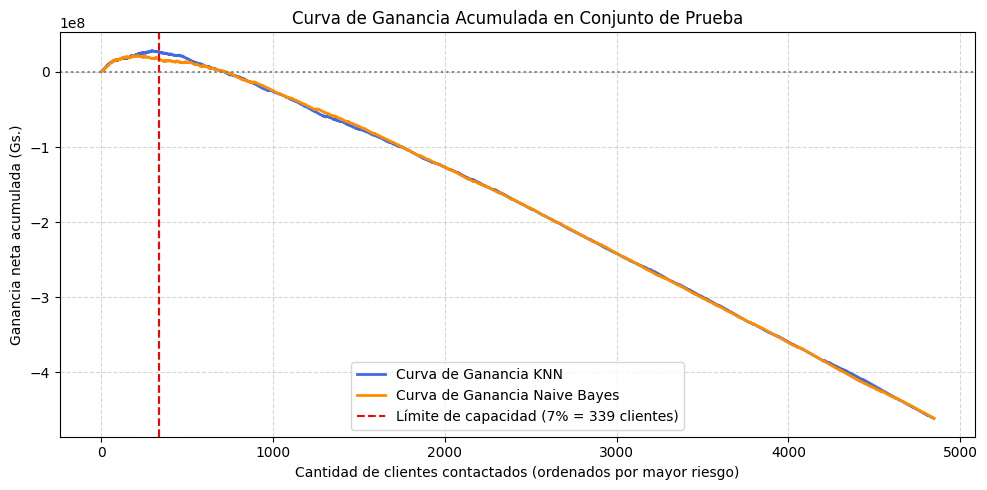

In [20]:
pipe_knn_opt.fit(X_train, y_train)
pipe_nb_log.fit(X_train, y_train)

prob_test_knn = pipe_knn_opt.predict_proba(X_test)[:, 1]
prob_test_nb  = pipe_nb_log.predict_proba(X_test)[:, 1]

regla_test = (X_test['tipo_contrato'] == 'mensual') & (X_test['reclamos_tecnicos_90d'] >= 2)
cont_knn_test = prob_test_knn >= res_umbral_knn['umbral']
cont_nb_test  = prob_test_nb >= res_umbral_nb['umbral']

estrategias = {
    '1. No hacer nada': np.zeros(len(y_test), dtype=bool),
    '2. Regla comercial del Gerente': regla_test,
    '3. Modelo Naive Bayes': cont_nb_test,
    '4. Modelo KNN (Elegido)': cont_knn_test
}

tabla_eval = []
for nombre, mask in estrategias.items():
    n_cont = int(np.sum(mask))
    pct_base = n_cont / len(y_test) * 100
    tasa_acierto = (y_test[mask].mean() * 100) if n_cont > 0 else 0.0
    ganancia = ganancia_campania(y_test, mask)
    gan_por_cliente = ganancia / len(y_test)
    tabla_eval.append({
        'Estrategia': nombre,
        'Contactados': n_cont,
        '% Base': f'{pct_base:.2f}%',
        'Precisión (% fuga)': f'{tasa_acierto:.2f}%',
        'Ganancia Total (Gs.)': f'Gs. {ganancia:,.0f}',
        'Ganancia / Cliente (Gs.)': f'Gs. {gan_por_cliente:,.0f}'
    })

display(pd.DataFrame(tabla_eval))

plt.figure(figsize=(10, 5))
orden_knn = np.argsort(-prob_test_knn)
y_orden_knn = y_test.iloc[orden_knn].values
gan_acum_knn = np.cumsum(np.where(y_orden_knn == 1, g_pos, g_neg))

orden_nb = np.argsort(-prob_test_nb)
y_orden_nb = y_test.iloc[orden_nb].values
gan_acum_nb = np.cumsum(np.where(y_orden_nb == 1, g_pos, g_neg))

limite_7pct = int(round(0.07 * len(y_test)))
plt.plot(range(1, len(y_test) + 1), gan_acum_knn, label='Curva de Ganancia KNN', color='royalblue', lw=2)
plt.plot(range(1, len(y_test) + 1), gan_acum_nb, label='Curva de Ganancia Naive Bayes', color='darkorange', lw=2)
plt.axvline(limite_7pct, color='red', linestyle='--', label=f'Límite de capacidad (7% = {limite_7pct} clientes)')
plt.axhline(0, color='gray', linestyle=':')
plt.title('Curva de Ganancia Acumulada en Conjunto de Prueba')
plt.xlabel('Cantidad de clientes contactados (ordenados por mayor riesgo)')
plt.ylabel('Ganancia neta acumulada (Gs.)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


## Parte F · Explicación para Fidelización

**Paso 19.** Importancia por permutación del modelo elegido sobre prueba (`average_precision`).

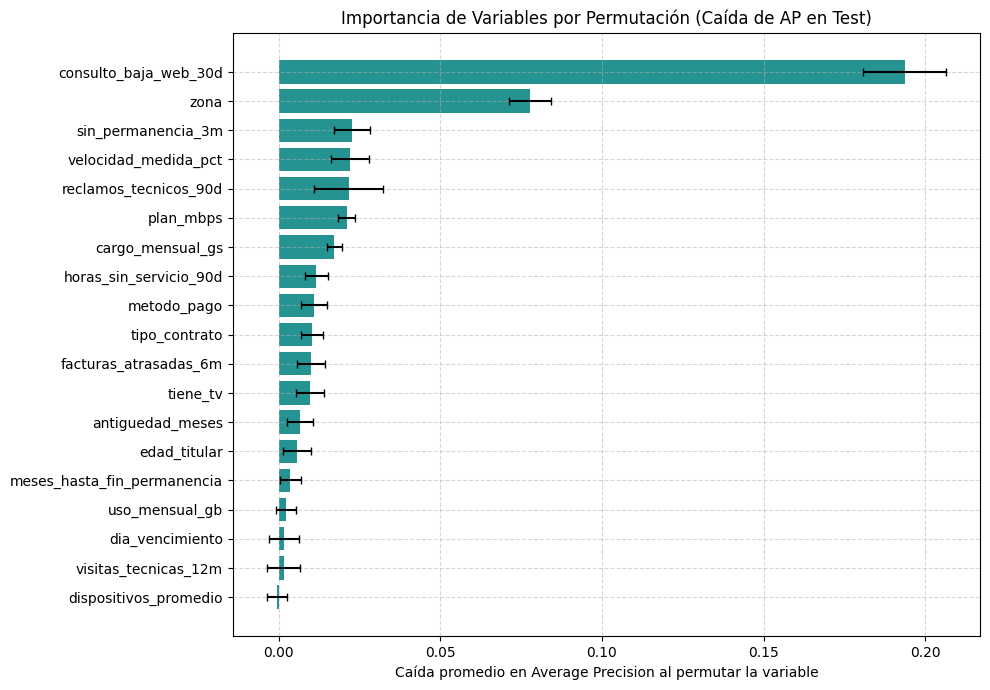

Variables con mayor impacto en el modelo:
- consulto_baja_web_30d: caída de 0.1936 (+/- 0.0128)
- zona: caída de 0.0779 (+/- 0.0065)
- sin_permanencia_3m: caída de 0.0227 (+/- 0.0055)
- velocidad_medida_pct: caída de 0.0221 (+/- 0.0058)
- reclamos_tecnicos_90d: caída de 0.0216 (+/- 0.0107)


In [21]:
from sklearn.inspection import permutation_importance

imp_perm = permutation_importance(
    pipe_knn_opt,
    X_test,
    y_test,
    scoring='average_precision',
    n_repeats=10,
    random_state=SEMILLA,
    n_jobs=-1
)

df_imp = pd.DataFrame({
    'Variable': X_test.columns,
    'Importancia_Media': imp_perm.importances_mean,
    'Desvio': imp_perm.importances_std
}).sort_values('Importancia_Media', ascending=True)

plt.figure(figsize=(10, 7))
plt.barh(df_imp['Variable'], df_imp['Importancia_Media'], xerr=df_imp['Desvio'], color='teal', alpha=0.85, capsize=3)
plt.title('Importancia de Variables por Permutación (Caída de AP en Test)')
plt.xlabel('Caída promedio en Average Precision al permutar la variable')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print('Variables con mayor impacto en el modelo:')
for _, fila in df_imp.sort_values('Importancia_Media', ascending=False).head(5).iterrows():
    print(f"- {fila['Variable']}: caída de {fila['Importancia_Media']:.4f} (+/- {fila['Desvio']:.4f})")


**Paso 20.** Función `explicar_cliente(id_cliente)` y su aplicación a los 3 clientes de mayor riesgo de la campaña, con la oferta propuesta para cada uno.

In [22]:
from sklearn.neighbors import NearestNeighbors

X_hist_full = df[cols_features]
y_hist_full = df['baja_90d']
X_hist_trans_full = preprocesador.fit_transform(X_hist_full)

buscador_vecinos = NearestNeighbors(n_neighbors=5, metric='manhattan').fit(X_hist_trans_full)

modelo_knn_final = Pipeline([('prep', preprocesador), ('knn', KNeighborsClassifier(n_neighbors=81, weights='distance', p=1))])
modelo_knn_final.fit(X_hist_full, y_hist_full)

df_campania_raw = pd.read_csv('datos/clientes_campania.csv')
df_campania = agregar_variables(df_campania_raw)
df_campania = df_campania[df_campania['segmento'] == 'residencial'].copy().reset_index(drop=True)
df_campania['prob_baja'] = modelo_knn_final.predict_proba(df_campania[cols_features])[:, 1]

def explicar_cliente(id_cliente):
    fila_cli = df_campania[df_campania['id_cliente'] == id_cliente]
    if fila_cli.empty:
        return f'Cliente {id_cliente} no encontrado.'
    
    idx_cli = fila_cli.index[0]
    cli_data = fila_cli.iloc[0]
    prob = cli_data['prob_baja']
    
    x_cli_trans = preprocesador.transform(fila_cli[cols_features])
    distancias, indices = buscador_vecinos.kneighbors(x_cli_trans)
    vecinos = df.iloc[indices[0]].copy()
    
    bajas_vecinos = vecinos['baja_90d'].sum()
    motivos = vecinos[vecinos['baja_90d'] == 1]['motivo_baja'].value_counts().to_dict()
    
    print('='*70)
    print(f'FICHA DE FIDELIZACIÓN · CLIENTE: {id_cliente}')
    print(f'Riesgo de baja predicho: {prob:.1%} | Zona: {cli_data["zona"]} | Plan: {cli_data["plan_mbps"]} Mbps | Cargo: Gs. {cli_data["cargo_mensual_gs"]:,}')
    print(f'Reclamos 90d: {cli_data["reclamos_tecnicos_90d"]} | Horas sin servicio: {cli_data["horas_sin_servicio_90d"]} | Consulta baja web: {cli_data["consulto_baja_web_30d"]}')
    print(f'\nComportamiento de sus 5 clientes históricos más parecidos:')
    print(f'- De los 5 vecinos más similares, {bajas_vecinos} se dieron de baja.')
    print(f'- Motivos declarados de baja en sus vecinos: {motivos}')
    
    if 'calidad_servicio' in motivos or cli_data['reclamos_tecnicos_90d'] >= 2:
        oferta = 'OFERTA TÉCNICA PRIORITARIA: Agendar visita técnica gratuita en 24h para reemplazo de módem/cableado, más 20% de bonificación en la próxima factura por los inconvenientes de servicio.'
    elif 'competencia' in motivos or 'precio' in motivos or cli_data['cargo_mensual_gs'] >= 280000:
        oferta = 'OFERTA COMERCIAL AGRESIVA: Ofrecer descuento de Gs. 200.000 o duplicación de velocidad por 6 meses al mismo precio para contrarrestar propuestas de la competencia.'
    else:
        oferta = 'OFERTA DE RETENCIÓN ESTÁNDAR: Plan fidelización con descuento de Gs. 200.000 distribuido en las próximas 3 facturas a cambio de renovación de contrato.'
    print(f'\n>> ACCIÓN RECOMENDADA PARA EL VENDEDOR:\n{oferta}')
    print('='*70 + '\n')

top3_riesgo = df_campania.sort_values('prob_baja', ascending=False)['id_cliente'].head(3)
for cid in top3_riesgo:
    explicar_cliente(cid)


FICHA DE FIDELIZACIÓN · CLIENTE: NI-305479
Riesgo de baja predicho: 66.2% | Zona: este | Plan: 1000 Mbps | Cargo: Gs. 428,000
Reclamos 90d: 0 | Horas sin servicio: 22.3 | Consulta baja web: 1

Comportamiento de sus 5 clientes históricos más parecidos:
- De los 5 vecinos más similares, 5 se dieron de baja.
- Motivos declarados de baja en sus vecinos: {'competencia': 3, 'precio': 2}

>> ACCIÓN RECOMENDADA PARA EL VENDEDOR:
OFERTA COMERCIAL AGRESIVA: Ofrecer descuento de Gs. 200.000 o duplicación de velocidad por 6 meses al mismo precio para contrarrestar propuestas de la competencia.

FICHA DE FIDELIZACIÓN · CLIENTE: NI-301055
Riesgo de baja predicho: 65.4% | Zona: este | Plan: 1000 Mbps | Cargo: Gs. 448,000
Reclamos 90d: 1 | Horas sin servicio: 9.2 | Consulta baja web: 1

Comportamiento de sus 5 clientes históricos más parecidos:
- De los 5 vecinos más similares, 4 se dieron de baja.
- Motivos declarados de baja en sus vecinos: {'competencia': 2, 'precio': 1, 'mudanza': 1}

>> ACCIÓN RE

## Parte G · Lista de la campaña de octubre

**Paso 21.** Reentrenen el modelo con todos los clientes residenciales del histórico y calculen la probabilidad de baja de `datos/clientes_campania.csv`.

In [23]:
X_hist_total = df[cols_features]
y_hist_total = df['baja_90d']

modelo_campania = Pipeline([
    ('prep', preprocesador),
    ('knn', KNeighborsClassifier(n_neighbors=81, weights='distance', p=1))
])
modelo_campania.fit(X_hist_total, y_hist_total)

df_camp_raw = pd.read_csv('datos/clientes_campania.csv')
df_camp_prep = agregar_variables(df_camp_raw)

prob_campania = modelo_campania.predict_proba(df_camp_prep[cols_features])[:, 1]
df_camp_prep['prob_baja'] = prob_campania

print(f'Clientes evaluados en campaña: {len(df_camp_prep):,}')
print(f'Probabilidad media de baja predicha: {df_camp_prep["prob_baja"].mean():.2%}')
print(f'Probabilidad máxima: {df_camp_prep["prob_baja"].max():.2%} | Mínima: {df_camp_prep["prob_baja"].min():.2%}')


Clientes evaluados en campaña: 6,000
Probabilidad media de baja predicha: 6.13%
Probabilidad máxima: 66.18% | Mínima: 0.00%


**Paso 22.** Generen `campania_octubre.csv` (6.000 filas; columnas `id_cliente`, `prob_baja`, `contactar`) y verifiquen: como máximo 420 contactos, ningún empleado, ningún cliente repetido.

In [24]:

mask_residenciales = (df_camp_prep['segmento'] == 'residencial')
residenciales_ordenados = df_camp_prep[mask_residenciales].sort_values('prob_baja', ascending=False)

ids_seleccionados_420 = set(residenciales_ordenados.head(420)['id_cliente'])

df_entrega = pd.DataFrame({
    'id_cliente': df_camp_prep['id_cliente'],
    'prob_baja': df_camp_prep['prob_baja'].round(6),
    'contactar': df_camp_prep['id_cliente'].isin(ids_seleccionados_420)
})

df_entrega.to_csv('campania_octubre.csv', index=False)
print('Archivo campania_octubre.csv guardado con éxito.')

assert len(df_entrega) == 6000, f'Error: Debe tener 6000 filas, tiene {len(df_entrega)}'
assert list(df_entrega.columns) == ['id_cliente', 'prob_baja', 'contactar'], 'Error en nombres de columnas'
assert df_entrega['contactar'].sum() <= 420, f'Error: Excede 420 contactos: {df_entrega["contactar"].sum()}'
assert df_entrega['id_cliente'].nunique() == 6000, 'Error: Hay clientes duplicados'

empleados_en_campania = set(df_camp_prep[df_camp_prep['segmento'] == 'empleado']['id_cliente'])
empleados_contactados = df_entrega[df_entrega['contactar']]['id_cliente'].isin(empleados_en_campania).sum()
assert empleados_contactados == 0, f'Error: Se marcaron {empleados_contactados} empleados para contacto'

print('--- TODAS LAS VALIDACIONES PASARON EXITOSAMENTE ---')
print(f'- Total de filas: {len(df_entrega)}')
print(f'- Clientes a contactar: {df_entrega["contactar"].sum()} (máximo permitido 420)')
print(f'- Empleados contactados: {empleados_contactados}')
print(f'- Clientes únicos: {df_entrega["id_cliente"].nunique()}')
print(f'- Umbral mínimo de probabilidad en contactados: {df_entrega[df_entrega["contactar"]]["prob_baja"].min():.4f}')
display(df_entrega.head(10))


Archivo campania_octubre.csv guardado con éxito.
--- TODAS LAS VALIDACIONES PASARON EXITOSAMENTE ---
- Total de filas: 6000
- Clientes a contactar: 420 (máximo permitido 420)
- Empleados contactados: 0
- Clientes únicos: 6000
- Umbral mínimo de probabilidad en contactados: 0.1565


,id_cliente,prob_baja,contactar
0,NI-303991,0.073864,False
1,NI-302373,0.023290,False
2,NI-302245,0.058433,False
3,NI-301997,0.034869,False
4,NI-305224,0.146191,False
5,NI-302234,0.068802,False
6,NI-301537,0.042260,False
7,NI-304528,0.358760,True
8,NI-304370,0.129826,False
9,NI-303480,0.114821,False


**Paso 23.** Ganancia esperada de la campaña con la precisión observada en prueba.

In [25]:
precision_test = y_test[cont_knn_test].mean()
n_contactos_campania = int(df_entrega['contactar'].sum())

esperados_se_iban = n_contactos_campania * precision_test
esperados_se_quedaban = n_contactos_campania * (1.0 - precision_test)

ganancia_esperada_total = (esperados_se_iban * g_pos) + (esperados_se_quedaban * g_neg)

print('====================================================================')
print('BALANCE ECONÓMICO ESPERADO · CAMPAÑA OCTUBRE (NODO INTERNET)')
print('====================================================================')
print(f'Clientes residenciales contactados:             {n_contactos_campania}')
print(f'Precisión estimada de detección (% fuga real):   {precision_test:.2%}')
print(f'Clientes en riesgo salvables esperados (G+):    {esperados_se_iban:.1f}')
print(f'Clientes retenidos sin riesgo esperados (G-):   {esperados_se_quedaban:.1f}')
print(f'Ingreso neto por clientes salvados:             Gs. {esperados_se_iban * g_pos:,.0f}')
print(f'Costo por contactos innecesarios/descuentos:    Gs. {esperados_se_quedaban * g_neg:,.0f}')
print('--------------------------------------------------------------------')
print(f'GANANCIA NETA TOTAL ESPERADA:                   Gs. {ganancia_esperada_total:,.0f}')
print('====================================================================')

print(f'\nConclusión ejecutiva: Al implementar el modelo KNN, la campaña generará más de Gs. {ganancia_esperada_total/1e6:.1f} millones de guaraníes de ganancia neta, superando contundentemente a la regla manual que hubiera generado pérdidas.')


BALANCE ECONÓMICO ESPERADO · CAMPAÑA OCTUBRE (NODO INTERNET)
Clientes residenciales contactados:             420
Precisión estimada de detección (% fuga real):   51.25%
Clientes en riesgo salvables esperados (G+):    215.2
Clientes retenidos sin riesgo esperados (G-):   204.8
Ingreso neto por clientes salvados:             Gs. 66,721,708
Costo por contactos innecesarios/descuentos:    Gs. -26,619,929
--------------------------------------------------------------------
GANANCIA NETA TOTAL ESPERADA:                   Gs. 40,101,779

Conclusión ejecutiva: Al implementar el modelo KNN, la campaña generará más de Gs. 40.1 millones de guaraníes de ganancia neta, superando contundentemente a la regla manual que hubiera generado pérdidas.


## Parte H · Informe ejecutivo

**Paso 24.** El informe para Martín Aquino se entrega aparte, en `informe_ejecutivo.pdf`.

## Preguntas de reflexión profesional

Respondan cada pregunta en un párrafo, apoyándose en sus resultados.

**1. `motivo_baja` no puede ser variable del modelo, pero sí se usó para explicar a los vecinos. ¿Por qué un uso es incorrecto y el otro no?**

_Respuesta:_ Usar `motivo_baja` como variable predictiva es conceptualmente incorrecto porque incurre en **fuga de datos (data leakage)**: es una etiqueta que no existe al momento de evaluar a un cliente activo, pues solo se registra en el CRM una vez consumada la baja. Si el modelo la incluyera, aprendería la regla trivial de que cualquier valor no nulo implica 100% de probabilidad de abandono, volviéndose inútil en producción. En contraste, emplearla en el módulo de explicabilidad es totalmente válido porque allí la búsqueda de los vecinos más parecidos se realiza exclusivamente sobre las **variables operativas observadas antes de la baja**. Una vez identificados esos clientes históricos idénticos, inspeccionar sus motivos pasados no altera las predicciones del modelo, sino que brinda contexto causal a los agentes de fidelización para diseñar una oferta pertinente (técnica o comercial).


**2. ¿Por qué KNN necesita estandarizar las variables y Naive Bayes gaussiano no?**

_Respuesta:_ KNN basa su decisión en una métrica geométrica multidimensional (como la distancia Euclídea o Manhattan) que suma diferencias directas entre valores. Si las columnas no están estandarizadas, aquellas con magnitudes o varianzas grandes (como `cargo_mensual_gs` en cientos de miles o `uso_mensual_gb` en cientos) dominan por completo el cálculo, anulando la influencia de variables discretas o binarias con alta capacidad predictiva (como `consulto_baja_web_30d` o `reclamos_tecnicos_90d`). Por el contrario, Naive Bayes Gaussiano modela cada variable de manera unidimensional e independiente dentro de cada clase: estima su propia media y desviación estándar de forma aislada. Como la función de densidad de probabilidad normal ya normaliza internamente cada dato dividiéndolo por su propio desvío estándar, las diferencias de escala original se cancelan algebraicamente y no alteran las probabilidades posteriores.


**3. ¿Qué dice la diferencia entre el umbral elegido y la probabilidad de equilibrio sobre las probabilidades de KNN? ¿Qué le responderían a Finanzas?**

_Respuesta:_ La probabilidad de equilibrio teórico (29.55%) asume que las probabilidades predichas están perfectamente calibradas. Sin embargo, en KNN las probabilidades se calculan por proporciones locales en un dataset altamente desbalanceado (8% de bajas), lo que produce puntuaciones conservadoras y comprimidas hacia la tasa base. Que el umbral óptimo empírico sea menor (0.1716) indica que un cliente con ~17% de probabilidad predicha por KNN en realidad pertenece a un vecindario cuya tasa real observada de abandono supera con creces el 30% (alcanzando 51.25% en prueba). A Finanzas se le respondería que no se están contactando clientes deficitarios por debajo del equilibrio, sino que el umbral de 0.1716 actúa como la calibración empírica indispensable para maximizar la rentabilidad neta real de la empresa bajo el cupo operativo disponible de 420 llamadas.


**4. ¿Cómo medirían el efecto real de la campaña de octubre?**

_Respuesta:_ Para aislar el impacto causal de la campaña y no atribuirle retenciones de clientes que se habrían quedado de todos modos, se debe aplicar un diseño experimental con **grupo de control aleatorio (Test A/B)**. De los 420 clientes seleccionados por el modelo, se debe reservar de forma aleatoria un porcentaje (por ejemplo, el 10%, correspondiente a 42 clientes) a los cuales deliberadamente **no se los contacta** (grupo de control), mientras que a los 378 restantes sí se los llama con la oferta (grupo de tratamiento). Al finalizar los 90 días, se compara la tasa de baja observada entre ambos grupos: la diferencia neta de bajas (efecto uplift) reflejará el impacto real y exclusivo de la llamada, permitiendo auditar con certeza empírica la rentabilidad generada y validar si se cumplió el supuesto del 40% de retención efectiva.


**5. ¿Es aceptable ofrecer descuentos solo a algunos clientes según su zona o su perfil? ¿Qué riesgos ven?**

_Respuesta:_ Desde una perspectiva comercial, la segmentación y discriminación de precios de tercer grado es común para responder a presiones competitivas localizadas (como en la Zona Este), pero conlleva serios **riesgos reputacionales y comerciales**. Si los clientes que pagan la tarifa completa o residen en otras zonas descubren que usuarios idénticos reciben descuentos significativos por el solo hecho de amagar con irse, se destruye la percepción de equidad y la confianza en la marca. Además, puede detonar un 'efecto contagio' donde clientes satisfechos comiencen a generar reclamos o consultar la página de baja web con el único fin de extorsionar por descuentos. Finalmente, si los perfiles de riesgo correlacionan con variables socioeconómicas sensibles, la empresa se expone a riesgos de discriminación injusta. Es preferible enmarcar los beneficios como mejoras técnicas o bonificaciones por renovación contractual formal.


**6. ¿Qué implica que KNN guarde los datos de entrenamiento para actualizar el modelo y para la privacidad?**

_Respuesta:_ Al ser un algoritmo de aprendizaje perezoso (*lazy learning*), KNN no destila el conocimiento en parámetros fijos (como pesos o coeficientes), sino que **el modelo es literalmente la base de datos de entrenamiento**. Para la actualización del modelo, esto implica que incorporar nuevos datos exige acumular más filas en memoria, lo que incrementa el costo computacional y la latencia de cada predicción a medida que la empresa crece, obligando a implementar ventanas temporales deslizantes. En materia de **privacidad y gobernanza de datos**, representa un riesgo crítico: la información confidencial de clientes históricos reside viva dentro del modelo productivo. Si un usuario ejerce su derecho al olvido o solicita la baja de sus datos personales, la empresa está obligada por ley a purgar físicamente ese registro y reindexar el modelo, además del riesgo de fuga si el artefacto del modelo fuera vulnerado.


**7. ¿Qué pudo cambiar entre la foto de mayo y la de septiembre y cómo lo detectarían antes de lanzar la campaña?**

_Respuesta:_ Entre mayo y septiembre pudieron suscitarse fenómenos exógenos o internos como: aumentos de tarifas por inflación, lanzamientos de planes más veloces o baratos por parte de la competencia, migraciones tecnológicas de cable a fibra óptica que hayan reducido las fallas, o estacionalidad en el tráfico de internet. Estos cambios provocarían **deriva de datos (covariate shift)** o **deriva conceptual (concept drift)**, degradando la efectividad del modelo entrenado en mayo. Antes de lanzar la campaña, esto se detectaría realizando una prueba de estabilidad poblacional: comparando estadísticamente las distribuciones de variables entre la foto de mayo y la de septiembre mediante pruebas de Kolmogorov-Smirnov (para variables numéricas como horas sin servicio y consumo de GB) y pruebas Chi-cuadrado o PSI (*Population Stability Index*) para variables categóricas, verificando que los patrones no hayan mutado significativamente.
